# Machine Learning: Wine Quality Prediction and Retail Customer Segmentation

This portfolio copy preserves the completed analytical work and saved outputs while removing institutional cover-sheet information.


## Import the required packages

In [1]:
# Packages for Task 1 - Supervised Learning (Wine Quality)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from math import sqrt

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%matplotlib inline
plt.rcParams['figure.figsize'] = (8, 5)
pd.set_option('display.max_columns', None)

In [2]:
# Packages for Task 2 - Unsupervised Learning (Online Retail)
import os
os.environ['OMP_NUM_THREADS'] = '1'  # avoid KMeans memory-leak warning on Windows

import scipy.cluster.hierarchy as shc
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

## 1. Task 1: Supervised Learning Using Wine Quality Dataset

### 1.1 Load and Explore the Data

In [3]:
# Load the dataset
wine = pd.read_csv('winequality-white.csv')
print('Shape:', wine.shape)
wine.head()

Shape: (4898, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [4]:
wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [5]:
# Check for duplicate rows
original_rows = len(wine)
dupe_count = wine.duplicated().sum()
dupe_pct = round(100 * dupe_count / original_rows, 2)
print('Exact duplicate rows:', dupe_count)
print('As % of dataset:', dupe_pct)
wine[wine.duplicated(keep=False)].sort_values(list(wine.columns)).head(10)

Exact duplicate rows: 937
As % of dataset: 19.13


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
4671,4.9,0.335,0.14,1.3,0.036,69.0,168.0,0.99212,3.47,0.46,10.466667,5
4672,4.9,0.335,0.14,1.3,0.036,69.0,168.0,0.99212,3.47,0.46,10.466667,5
3941,4.9,0.345,0.34,1.0,0.068,32.0,143.0,0.99138,3.24,0.40,10.100000,5
3950,4.9,0.345,0.34,1.0,0.068,32.0,143.0,0.99138,3.24,0.40,10.100000,5
2990,5.0,0.270,0.32,4.5,0.032,58.0,178.0,0.98956,3.45,0.31,12.600000,7
3007,5.0,0.270,0.32,4.5,0.032,58.0,178.0,0.98956,3.45,0.31,12.600000,7
1203,5.0,0.330,0.16,1.5,0.049,10.0,97.0,0.99170,3.48,0.44,10.700000,6
1204,5.0,0.330,0.16,1.5,0.049,10.0,97.0,0.99170,3.48,0.44,10.700000,6
1213,5.0,0.330,0.16,1.5,0.049,10.0,97.0,0.99170,3.48,0.44,10.700000,6
4444,5.0,0.350,0.25,7.8,0.031,24.0,116.0,0.99241,3.39,0.40,11.300000,6


In [6]:
wine = wine.drop_duplicates().reset_index(drop=True)
print('Shape after removing duplicates:', wine.shape)

Shape after removing duplicates: (3961, 12)


In [7]:
wine.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000,3961.000000
mean,6.839346,0.280538,0.334332,5.914819,0.045905,34.889169,137.193512,0.993790,3.195458,0.490351,10.589358,5.854835
std,0.866860,0.103437,0.122446,4.861646,0.023103,17.210021,43.129065,0.002905,0.151546,0.113523,1.217076,0.890683
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.600000,0.035000,23.000000,106.000000,0.991620,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,4.700000,0.042000,33.000000,133.000000,0.993500,3.180000,0.480000,10.400000,6.000000
75%,7.300000,0.330000,0.390000,8.900000,0.050000,45.000000,166.000000,0.995710,3.290000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


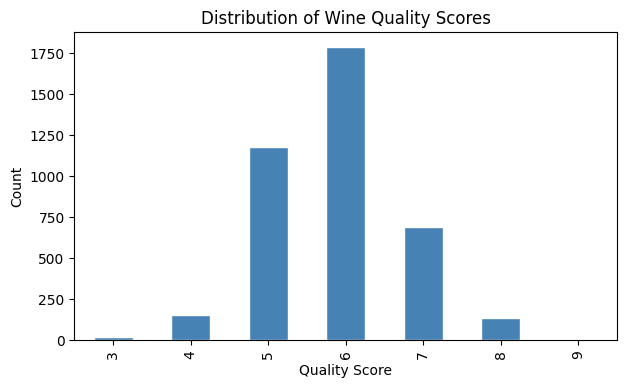

quality
3      20
4     153
5    1175
6    1788
7     689
8     131
9       5
Name: count, dtype: int64


In [8]:
# Distribution of the target variable
plt.figure(figsize=(7,4))
wine['quality'].value_counts().sort_index().plot(kind='bar', color='steelblue', edgecolor='white')
plt.title('Distribution of Wine Quality Scores')
plt.xlabel('Quality Score')
plt.ylabel('Count')
plt.show()

print(wine['quality'].value_counts().sort_index())

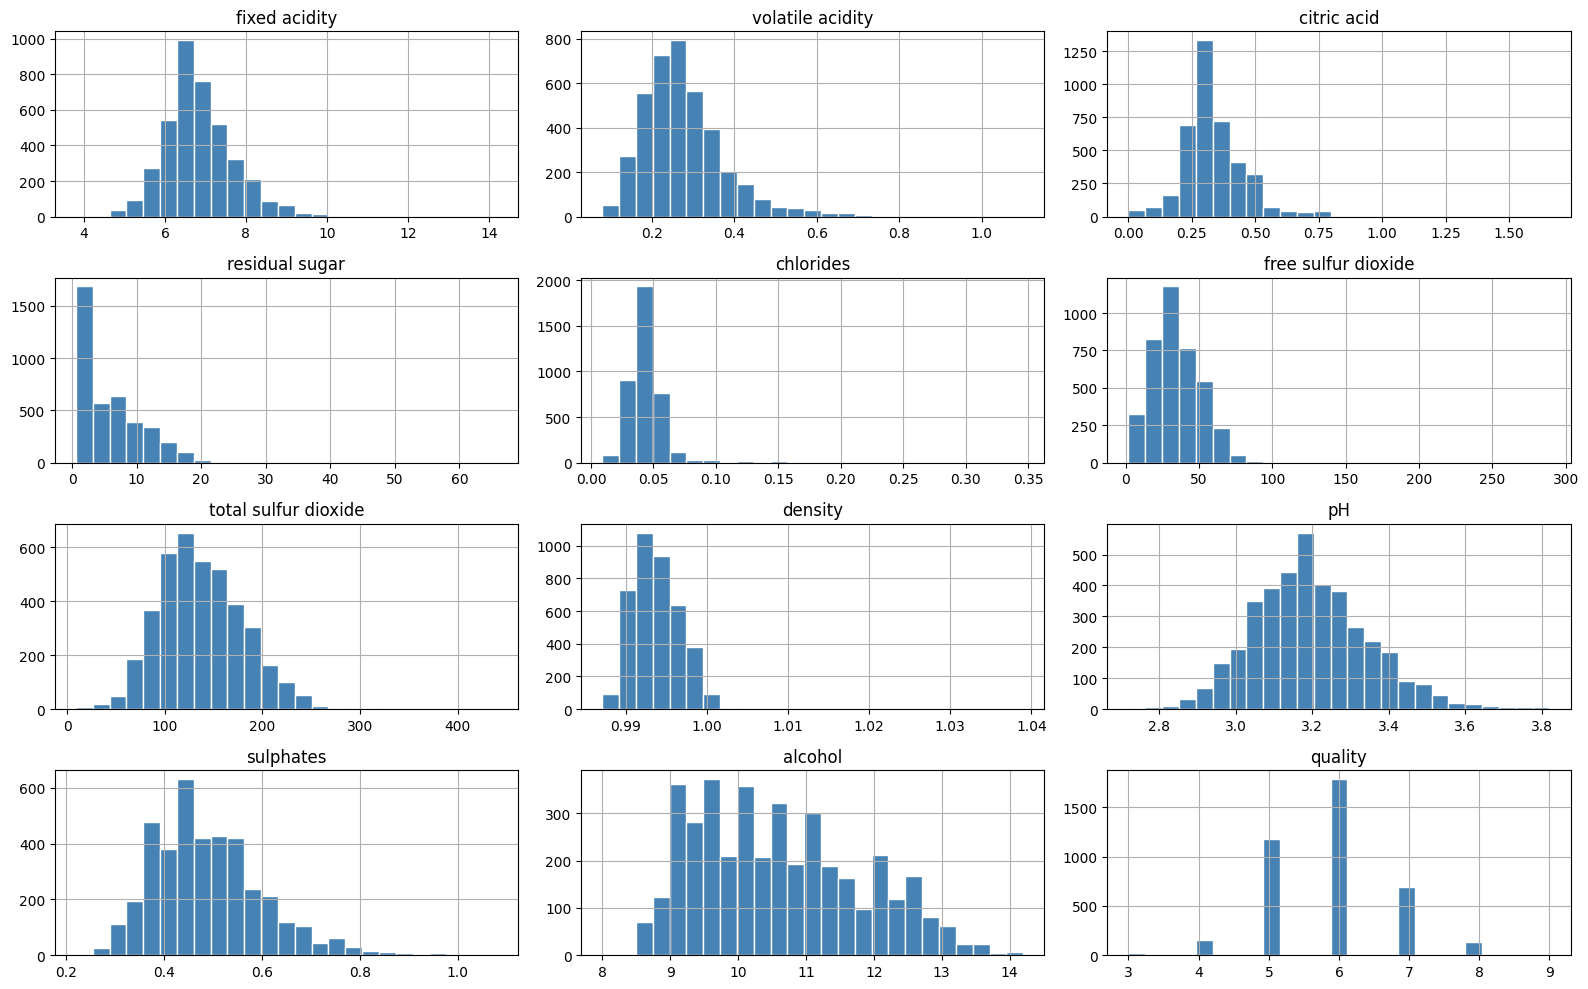

In [9]:
# Histograms of all numeric features
wine.hist(bins=25, figsize=(16,10), color='steelblue', edgecolor='white')
plt.tight_layout()
plt.show()

In [10]:
# Skewness of each numeric column, what the histograms above show
skewness = wine.skew().sort_values(ascending=False)
skewness

chlorides               4.969076
volatile acidity        1.641081
free sulfur dioxide     1.566680
residual sugar          1.333639
citric acid             1.310601
density                 1.273318
sulphates               0.937853
fixed acidity           0.696100
total sulfur dioxide    0.456800
pH                      0.455457
alcohol                 0.450697
quality                 0.112004
dtype: float64

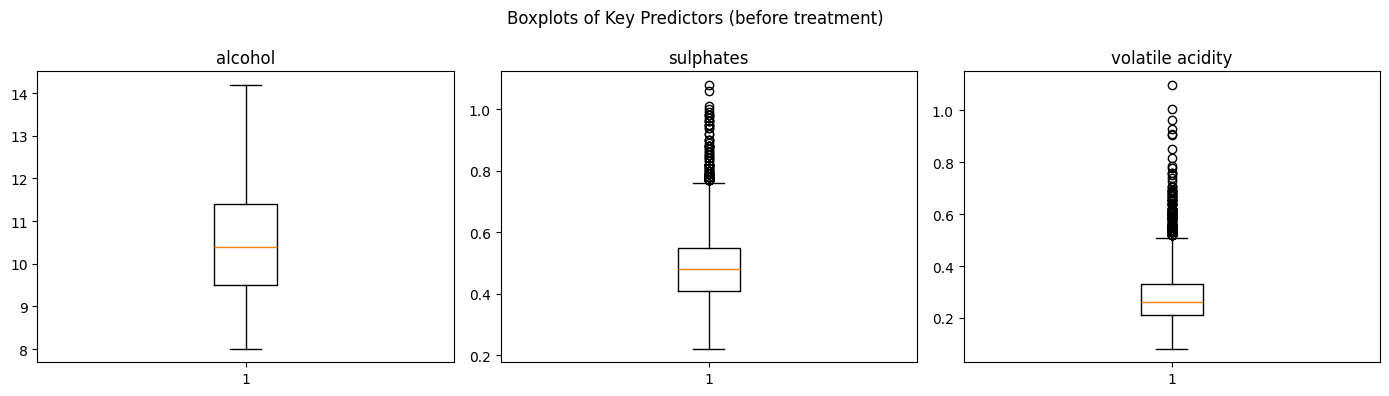

In [11]:
# Boxplots of key predictors highlighted in the assignment brief
key_predictors = ['alcohol', 'sulphates', 'volatile acidity']

fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, col in zip(axes, key_predictors):
    ax.boxplot(wine[col])
    ax.set_title(col)
plt.suptitle('Boxplots of Key Predictors (before treatment)')
plt.tight_layout()
plt.show()

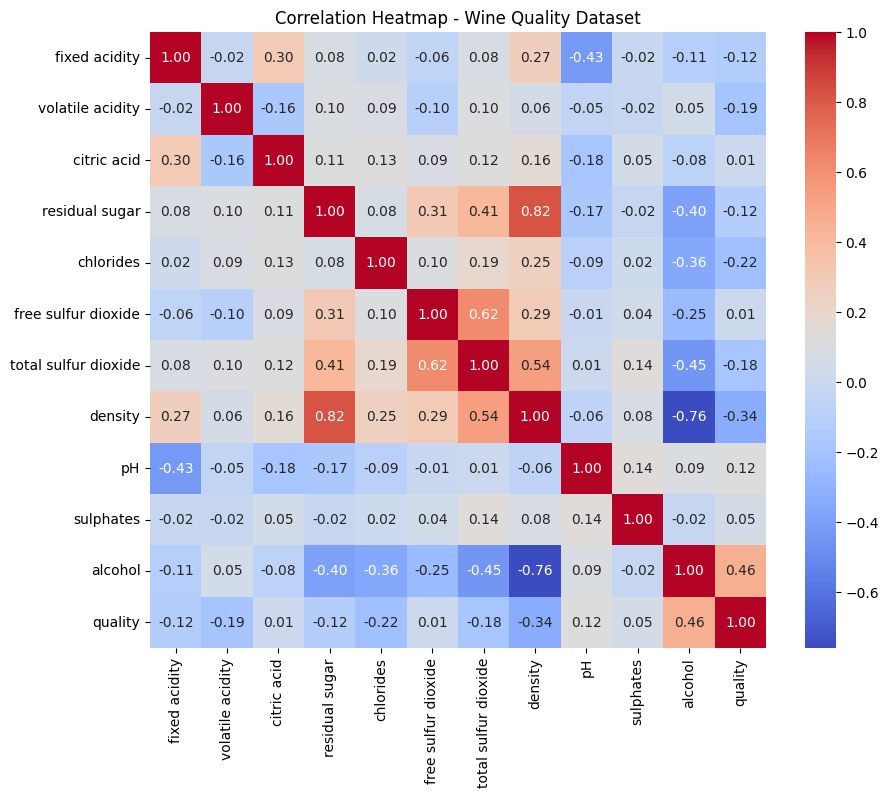

In [12]:
# Correlation heatmap for the whole data set since later on we only use training set
plt.figure(figsize=(10,8))
corr = wine.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', cbar=True, square=True)
plt.title('Correlation Heatmap - Wine Quality Dataset')
plt.show()

### 1.2 Data Preparation and Correlation Analysis

In [13]:
# Step 1: Check for missing values
print('Missing values per column:')
print(wine.isnull().sum())
print('\nTotal missing values:', wine.isnull().sum().sum())

Missing values per column:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Total missing values: 0


In [ ]:
#  split into train (80%) / test (20%)
X = wine.drop('quality', axis=1)
y = wine['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training samples:', X_train.shape[0])
print('Testing samples :', X_test.shape[0])

Training samples: 3168
Testing samples : 793


In [ ]:
#  Outlier detection & capping using the IQR method (bounds fitted on trainset only)
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

bounds = {col: iqr_bounds(X_train[col]) for col in X_train.columns}

outlier_counts = {
    col: ((X_train[col] < lo) | (X_train[col] > hi)).sum()
    for col, (lo, hi) in bounds.items()
}

outlier_table = pd.DataFrame({
    'Lower Bound': {c: b[0] for c, b in bounds.items()},
    'Upper Bound': {c: b[1] for c, b in bounds.items()},
    'Outliers in Train': outlier_counts,
    '% of Train Rows': {c: 100 * outlier_counts[c] / len(X_train) for c in outlier_counts},
}).sort_values('Outliers in Train', ascending=False)
outlier_table.round(3)

,Lower Bound,Upper Bound,Outliers in Train,% of Train Rows
citric acid,0.090,0.570,178,5.619
chlorides,0.013,0.073,143,4.514
volatile acidity,0.045,0.485,124,3.914
fixed acidity,4.800,8.800,75,2.367
sulphates,0.200,0.760,75,2.367
pH,2.790,3.590,34,1.073
free sulfur dioxide,-10.000,78.000,32,1.010
residual sugar,-9.200,19.600,19,0.600
total sulfur dioxide,17.500,253.500,13,0.410
density,0.985,1.002,6,0.189


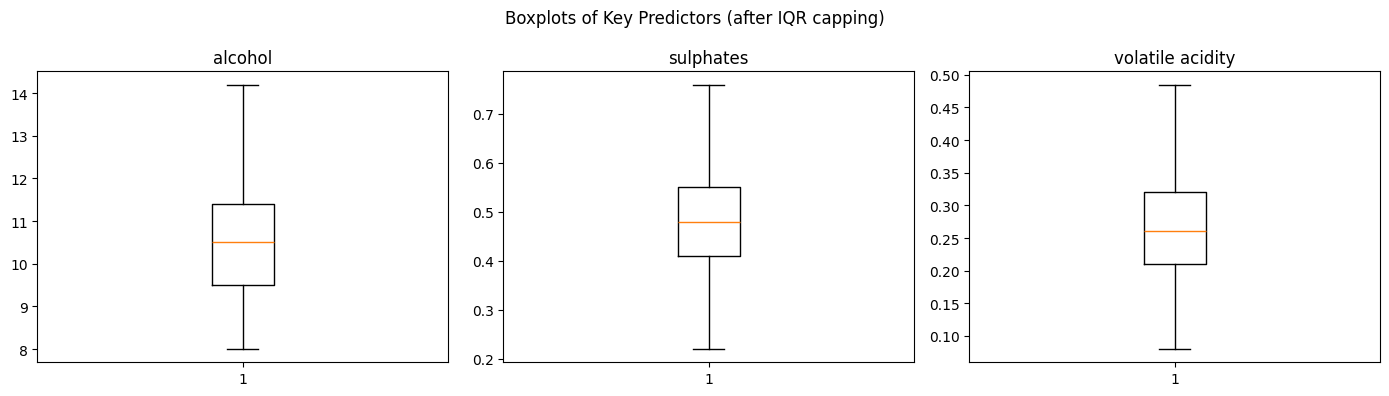

In [ ]:
# Cap via winsorize both train and test using the using train set boundaries
X_train_capped = X_train.copy()
X_test_capped = X_test.copy()

for col, (lo, hi) in bounds.items():
    X_train_capped[col] = X_train_capped[col].clip(lo, hi)
    X_test_capped[col] = X_test_capped[col].clip(lo, hi)

# Boxplots of the key predictors post capping
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, col in zip(axes, key_predictors):
    ax.boxplot(X_train_capped[col])
    ax.set_title(col)
plt.suptitle('Boxplots of Key Predictors (after IQR capping)')
plt.tight_layout()
plt.show()

In [17]:
# Step 4: Standardize the features (fit on train, apply to test)
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_capped), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_capped), columns=X_test.columns, index=X_test.index)

X_train_scaled.describe().T[['mean', 'std', 'min', 'max']]

,mean,std,min,max
fixed acidity,-4.396035e-16,1.000158,-2.498065,2.450424
volatile acidity,-5.657652e-16,1.000158,-2.219821,2.399587
citric acid,-9.420074e-17,1.000158,-2.323752,2.311194
residual sugar,-1.312082e-16,1.000158,-1.111563,2.896140
chlorides,-4.328748e-16,1.000158,-2.512029,2.493312
free sulfur dioxide,-1.805514e-16,1.000158,-2.025605,2.703317
total sulfur dioxide,-2.837237e-16,1.000158,-2.804274,2.769000
density,1.636289e-14,1.000158,-2.370698,2.867386
pH,-2.429033e-15,1.000158,-2.737867,2.682347
sulphates,-2.854058e-16,1.000158,-2.521143,2.524741


In [18]:
# Feature target correlation for feature only for training data to prevent leakage
train_corr = X_train.join(y_train).corr()
target_corr = train_corr['quality'].drop('quality').sort_values(key=abs, ascending=False)
print('Correlation of each feature with quality ')
target_corr

Correlation of each feature with quality 


alcohol                 0.465243
density                -0.337265
chlorides              -0.214250
volatile acidity       -0.204591
total sulfur dioxide   -0.181476
fixed acidity          -0.127207
residual sugar         -0.119727
pH                      0.114256
sulphates               0.059536
free sulfur dioxide     0.026000
citric acid             0.019396
Name: quality, dtype: float64

In [19]:
top6_features = target_corr.abs().sort_values(ascending=False).head(6).index.tolist()
print('Top 6 features most correlated with quality:')
print(top6_features)

feature_sets = {
    'All Features': X_train_scaled.columns.tolist(),
    'Top 6 Correlated Features': top6_features
}

Top 6 features most correlated with quality:
['alcohol', 'density', 'chlorides', 'volatile acidity', 'total sulfur dioxide', 'fixed acidity']


### 1.3 Build the Machine Learning Models

In [ ]:
def evaluate(model, X_tr, y_tr, X_te, y_te):
    y_fit = model.predict(X_tr)
    y_pred = model.predict(X_te)
    return {
        'train_mae': mean_absolute_error(y_tr, y_fit),
        'train_rmse': sqrt(mean_squared_error(y_tr, y_fit)),
        'train_r2': r2_score(y_tr, y_fit),
        'test_mae': mean_absolute_error(y_te, y_pred),
        'test_mse': mean_squared_error(y_te, y_pred),
        'test_rmse': sqrt(mean_squared_error(y_te, y_pred)),
        'test_r2': r2_score(y_te, y_pred),
    }

# Cross-validated RMSE, computed on the training set only.
# Model selection must not look at the test set since choosing the winner by test RMSE would turn the
# held out set into a selection set and make the reported score optimistically biased. cv_rmse
# uses 5fold cross validation inside the training data (cross_val_score, as in the Decision
# Trees practical). Selection uses cv_rmse; test metrics are reported afterwards as confirmation.
def cv_rmse(model, X_tr, y_tr, cv=5):
    scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring='neg_root_mean_squared_error')
    return -scores.mean()

results = []

#Linear Regression on both feature gourps
for fs_name, cols in feature_sets.items():
    lm = LinearRegression()
    lm.fit(X_train_scaled[cols], y_train)
    m = evaluate(lm, X_train_scaled[cols], y_train, X_test_scaled[cols], y_test)
    m['cv_rmse'] = cv_rmse(LinearRegression(), X_train_scaled[cols], y_train)
    results.append({'Model': 'Linear Regression', 'Feature Set': fs_name, **m})

pd.DataFrame(results)[['Model','Feature Set','cv_rmse','train_rmse','test_rmse','test_r2']].round(4)


,Model,Feature Set,cv_rmse,train_rmse,test_rmse,test_r2
0,Linear Regression,All Features,0.7364,0.7330,0.7670,0.2826
1,Linear Regression,Top 6 Correlated Features,0.7531,0.7516,0.7947,0.2300


In [ ]:
# Standardised Linear Regression coefficients.

lm_all = LinearRegression().fit(X_train_scaled, y_train)

coef_table = pd.DataFrame({
    'Coefficient (standardised X)': lm_all.coef_,
    'Correlation with quality (train)': target_corr.reindex(X_train_scaled.columns).values,
}, index=X_train_scaled.columns)
coef_table['|Coefficient|'] = coef_table['Coefficient (standardised X)'].abs()
coef_table = coef_table.sort_values('|Coefficient|', ascending=False).drop(columns='|Coefficient|')
print(f'Intercept: {lm_all.intercept_:.4f}  (mean predicted quality when every feature sits at its mean)')
coef_table.round(4)


Intercept: 5.8513  (mean predicted quality when every feature sits at its mean)


,Coefficient (standardised X),Correlation with quality (train)
density,-0.5656,-0.3373
residual sugar,0.4151,-0.1197
volatile acidity,-0.1566,-0.2046
pH,0.1487,0.1143
alcohol,0.1484,0.4652
free sulfur dioxide,0.1201,0.0260
fixed acidity,0.0859,-0.1272
sulphates,0.0804,0.0595
citric acid,0.0462,0.0194
chlorides,-0.0429,-0.2143


In [ ]:
# Decision Tree Regressor: compare several max_depth values on both feature sets 
for depth in [3, 5, 7, 10, None]:
    for fs_name, cols in feature_sets.items():
        dt = DecisionTreeRegressor(max_depth=depth, random_state=42)
        dt.fit(X_train_scaled[cols], y_train)
        m = evaluate(dt, X_train_scaled[cols], y_train, X_test_scaled[cols], y_test)
        m['cv_rmse'] = cv_rmse(DecisionTreeRegressor(max_depth=depth, random_state=42),
                               X_train_scaled[cols], y_train)
        results.append({'Model': f'Decision Tree (max_depth={depth})', 'Feature Set': fs_name, **m})

results_df = pd.DataFrame(results)
# Ranked by cross-validated RMSE 
results_df_sorted = results_df.sort_values('cv_rmse').reset_index(drop=True)
results_df_sorted[['Model','Feature Set','cv_rmse','train_rmse','test_rmse','train_r2','test_r2','test_mae']].round(4)


,Model,Feature Set,cv_rmse,train_rmse,test_rmse,train_r2,test_r2,test_mae
0,Linear Regression,All Features,0.7364,0.7330,0.7670,0.3167,0.2826,0.5913
1,Linear Regression,Top 6 Correlated Features,0.7531,0.7516,0.7947,0.2815,0.2300,0.6115
2,Decision Tree (max_depth=3),All Features,0.7625,0.7465,0.7894,0.2912,0.2401,0.6261
3,Decision Tree (max_depth=5),All Features,0.7638,0.7006,0.7963,0.3757,0.2269,0.6225
4,Decision Tree (max_depth=5),Top 6 Correlated Features,0.7655,0.7192,0.8029,0.3422,0.2140,0.6236
5,Decision Tree (max_depth=3),Top 6 Correlated Features,0.7674,0.7525,0.8072,0.2799,0.2055,0.6328
6,Decision Tree (max_depth=7),All Features,0.7925,0.6389,0.8549,0.4809,0.1089,0.6430
7,Decision Tree (max_depth=7),Top 6 Correlated Features,0.7998,0.6758,0.8495,0.4191,0.1202,0.6428
8,Decision Tree (max_depth=10),Top 6 Correlated Features,0.8630,0.5688,0.9351,0.5886,-0.0661,0.6862
9,Decision Tree (max_depth=10),All Features,0.8801,0.5153,0.9326,0.6623,-0.0606,0.6742


### 1.4 Evaluate and Improve the Model(s) Performance

Following the Decision Trees practical, use `GridSearchCV` to search `criterion`, `max_depth`, `min_samples_leaf` and `min_samples_split` jointly (5-fold CV, scored on negative RMSE) on the All-Features set.

In [ ]:
param_grid = {
    'criterion': ['squared_error', 'friedman_mse'],
    'max_depth': [3, 4, 5, 6, 7, 8, 10],
    'min_samples_leaf': [1, 5, 10, 20],
    'min_samples_split': [2, 10, 20]
}

# GridSearchCV is run on BOTH feature sets s.
grid_searches = {}
for fs_name, cols in feature_sets.items():
    gs_fs = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid=param_grid,
                         scoring='neg_root_mean_squared_error', cv=5, n_jobs=-1)
    gs_fs.fit(X_train_scaled[cols], y_train)
    grid_searches[fs_name] = gs_fs
    print(f'{fs_name:28s} best CV RMSE = {-gs_fs.best_score_:.4f}   params = {gs_fs.best_params_}')

# for future ref
gs = grid_searches['All Features']


All Features                 best CV RMSE = 0.7538   params = {'criterion': 'squared_error', 'max_depth': 5, 'min_samples_leaf': 20, 'min_samples_split': 2}


Top 6 Correlated Features    best CV RMSE = 0.7623   params = {'criterion': 'squared_error', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 20}


In [ ]:
# Evaluate both tuned trees. The CV score comes from the grid search itself.
for fs_name, gs_fs in grid_searches.items():
    cols = feature_sets[fs_name]
    m = evaluate(gs_fs.best_estimator_, X_train_scaled[cols], y_train, X_test_scaled[cols], y_test)
    m['cv_rmse'] = -gs_fs.best_score_          # already a 5-fold CV score on the training set
    results.append({'Model': 'Decision Tree (GridSearchCV-tuned)', 'Feature Set': fs_name, **m})

results_df = pd.DataFrame(results)
results_df_sorted = results_df.sort_values('cv_rmse').reset_index(drop=True)
results_df_sorted[['Model','Feature Set','cv_rmse','train_rmse','test_rmse','train_r2','test_r2','test_mae','test_mse']].round(4)


,Model,Feature Set,cv_rmse,train_rmse,test_rmse,train_r2,test_r2,test_mae,test_mse
0,Linear Regression,All Features,0.7364,0.7330,0.7670,0.3167,0.2826,0.5913,0.5883
1,Linear Regression,Top 6 Correlated Features,0.7531,0.7516,0.7947,0.2815,0.2300,0.6115,0.6315
2,Decision Tree (GridSearchCV-tuned),All Features,0.7538,0.7071,0.7874,0.3641,0.2440,0.6135,0.6201
3,Decision Tree (GridSearchCV-tuned),Top 6 Correlated Features,0.7623,0.7230,0.8050,0.3352,0.2098,0.6252,0.6480
4,Decision Tree (max_depth=3),All Features,0.7625,0.7465,0.7894,0.2912,0.2401,0.6261,0.6232
5,Decision Tree (max_depth=5),All Features,0.7638,0.7006,0.7963,0.3757,0.2269,0.6225,0.6341
6,Decision Tree (max_depth=5),Top 6 Correlated Features,0.7655,0.7192,0.8029,0.3422,0.2140,0.6236,0.6447
7,Decision Tree (max_depth=3),Top 6 Correlated Features,0.7674,0.7525,0.8072,0.2799,0.2055,0.6328,0.6516
8,Decision Tree (max_depth=7),All Features,0.7925,0.6389,0.8549,0.4809,0.1089,0.6430,0.7308
9,Decision Tree (max_depth=7),Top 6 Correlated Features,0.7998,0.6758,0.8495,0.4191,0.1202,0.6428,0.7216


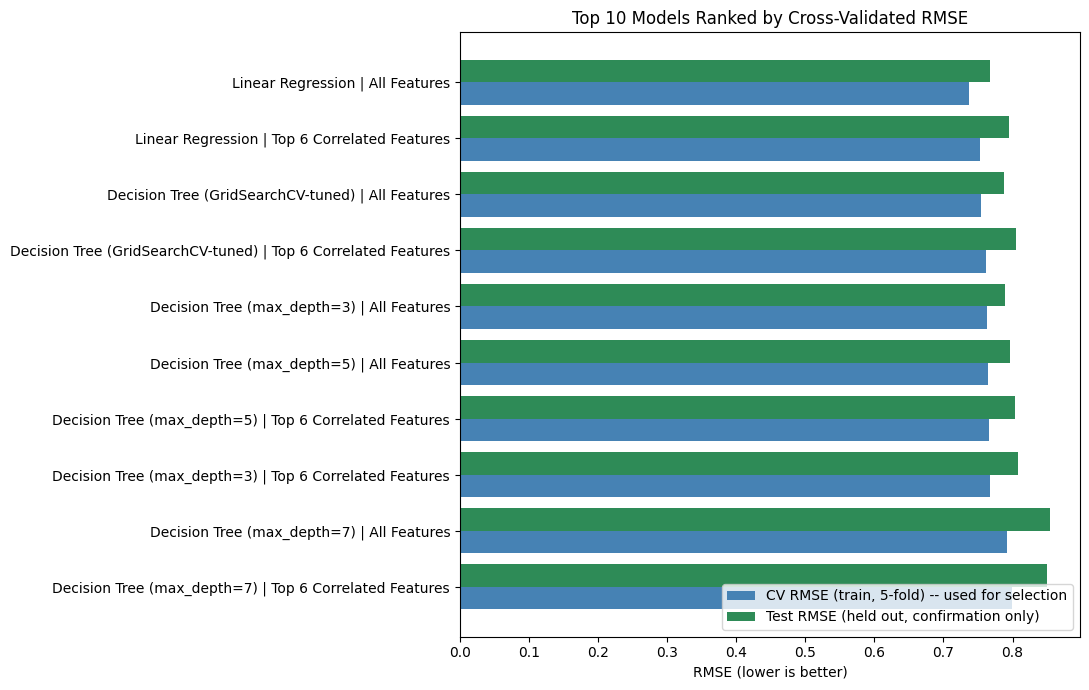

In [ ]:
# Models ranked by crossvalidated RMSE, with the held out test RMSE shown alongside.
plot_df = results_df_sorted.head(10).iloc[::-1]
labels = plot_df['Model'] + ' | ' + plot_df['Feature Set']
ypos = np.arange(len(plot_df))

plt.figure(figsize=(11,7))
plt.barh(ypos - 0.2, plot_df['cv_rmse'],   height=0.4, color='steelblue', label='CV RMSE (train, 5-fold) -- used for selection')
plt.barh(ypos + 0.2, plot_df['test_rmse'], height=0.4, color='seagreen',  label='Test RMSE (held out, confirmation only)')
plt.yticks(ypos, labels)
plt.xlabel('RMSE (lower is better)')
plt.title('Top 10 Models Ranked by Cross-Validated RMSE')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()


In [ ]:
# Winner is selected on CV RMSE
best_row = results_df_sorted.iloc[0]
print('Best model (selected on 5fold CV over the TRAINING set only):')
print(f"  {best_row['Model']} | {best_row['Feature Set']}")
print(f"  CV RMSE  : {best_row['cv_rmse']:.4f}")
print()
print('Held-out test performance (reported AFTER selection, not used to make it):')
print(f"  Test MAE : {best_row['test_mae']:.4f}")
print(f"  Test MSE : {best_row['test_mse']:.4f}")
print(f"  Test RMSE: {best_row['test_rmse']:.4f}")
print(f"  Test R2  : {best_row['test_r2']:.4f}")
print(f"  (Train RMSE: {best_row['train_rmse']:.4f}, Train R2: {best_row['train_r2']:.4f}  gap check for overfitting)")

# Sanity check: does CV-based selection agree with test-based selection?
test_winner = results_df_sorted.sort_values('test_rmse').iloc[0]
agree = (test_winner['Model'] == best_row['Model']) and (test_winner['Feature Set'] == best_row['Feature Set'])
print()
print(f"Would selecting on test RMSE have picked the same model? {'Yes' if agree else 'No'}"
      f"  ({test_winner['Model']} | {test_winner['Feature Set']})")


Best model (selected on 5-fold CV over the TRAINING set only):
  Linear Regression | All Features
  CV RMSE  : 0.7364

Held-out test performance (reported AFTER selection, not used to make it):
  Test MAE : 0.5913
  Test MSE : 0.5883
  Test RMSE: 0.7670
  Test R2  : 0.2826
  (Train RMSE: 0.7330, Train R2: 0.3167 -- gap check for overfitting)

Would selecting on test RMSE have picked the same model? Yes  (Linear Regression | All Features)


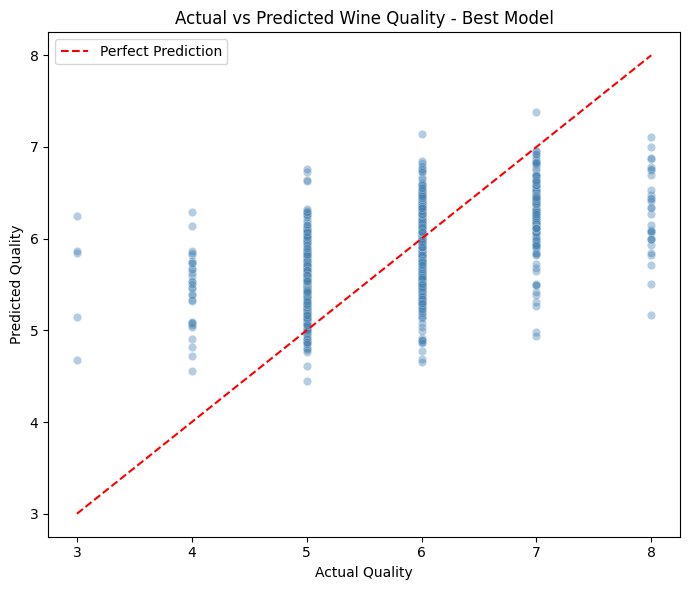

In [ ]:
# Refit the best model to get predictions for actual vs predict
best_cols = feature_sets[best_row['Feature Set']]
if 'GridSearchCV' in best_row['Model']:
    final_model = grid_searches[best_row['Feature Set']].best_estimator_
elif best_row['Model'] == 'Linear Regression':
    final_model = LinearRegression().fit(X_train_scaled[best_cols], y_train)
else:
    depth_str = best_row['Model'].split('max_depth=')[1].rstrip(')')
    depth = None if depth_str == 'None' else int(depth_str)
    final_model = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_train_scaled[best_cols], y_train)

y_pred_best = final_model.predict(X_test_scaled[best_cols])

plt.figure(figsize=(7,6))
plt.scatter(y_test, y_pred_best, alpha=0.4, color='steelblue', edgecolors='white', linewidth=0.3)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect Prediction')
plt.xlabel('Actual Quality')
plt.ylabel('Predicted Quality')
plt.title('Actual vs Predicted Wine Quality - Best Model')
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# Repeat the whole pipeline across 20 different train/test splits.

seed_rows = []
for rs in range(20):
    Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(X, y, test_size=0.2, random_state=rs)

    bounds_s = {col: iqr_bounds(Xtr_s[col]) for col in Xtr_s.columns}
    Xtr_capped, Xte_capped = Xtr_s.copy(), Xte_s.copy()
    for col, (lo, hi) in bounds_s.items():
        Xtr_capped[col] = Xtr_capped[col].clip(lo, hi)
        Xte_capped[col] = Xte_capped[col].clip(lo, hi)

    scaler_s = StandardScaler()
    Xtr_scaled_s = scaler_s.fit_transform(Xtr_capped)
    Xte_scaled_s = scaler_s.transform(Xte_capped)

    lm_s = LinearRegression().fit(Xtr_scaled_s, ytr_s)
    pred_s = lm_s.predict(Xte_scaled_s)

    seed_rows.append({
        'random_state': rs,
        'test_rmse': sqrt(mean_squared_error(yte_s, pred_s)),
        'test_r2': r2_score(yte_s, pred_s),
    })

seed_df = pd.DataFrame(seed_rows)
print('Linear Regression / All Features across 20 different train-test splits:')
print(seed_df[['test_rmse', 'test_r2']].describe().round(4).to_string())

Linear Regression / All Features across 20 different train-test splits:
       test_rmse  test_r2
count    20.0000  20.0000
mean      0.7395   0.3070
std       0.0208   0.0206
min       0.7140   0.2679
25%       0.7252   0.2940
50%       0.7356   0.3122
75%       0.7474   0.3190
max       0.8033   0.3491


Reported split (random_state=42): RMSE 0.7670, R2 0.2826
Across 20 splits               : RMSE 0.7395 (sd 0.0208, range 0.7140-0.8033)
95% of the 20 splits produced a LOWER (better) test RMSE than the reported split.


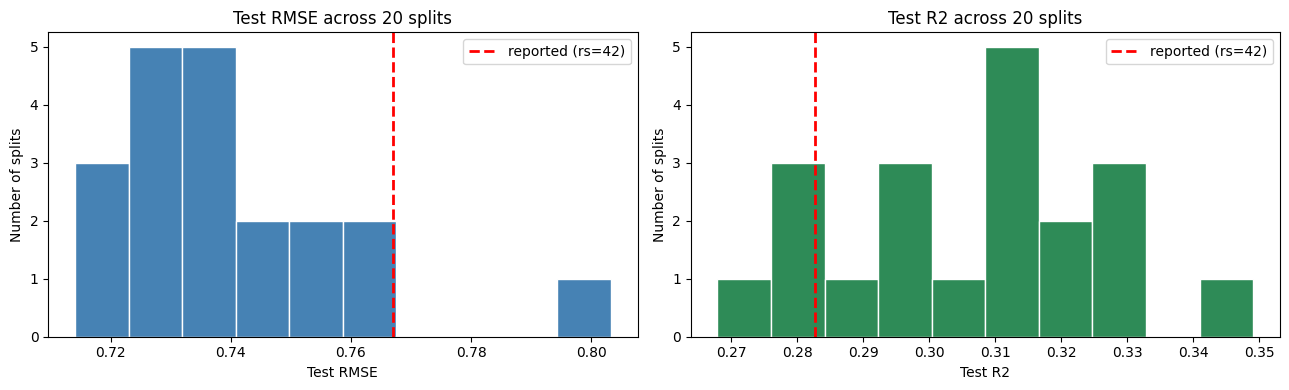

In [29]:
# Where does the reported seed 42 sit within that spread?
rmse_42 = results_df_sorted.loc[0, 'test_rmse']
r2_42   = results_df_sorted.loc[0, 'test_r2']
pct = (seed_df['test_rmse'] < rmse_42).mean() * 100

print(f'Reported split (random_state=42): RMSE {rmse_42:.4f}, R2 {r2_42:.4f}')
print(f'Across 20 splits               : RMSE {seed_df["test_rmse"].mean():.4f} '
      f'(sd {seed_df["test_rmse"].std():.4f}, range {seed_df["test_rmse"].min():.4f}'
      f'-{seed_df["test_rmse"].max():.4f})')
print(f'{pct:.0f}% of the 20 splits produced a LOWER (better) test RMSE than the reported split.')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(seed_df['test_rmse'], bins=10, color='steelblue', edgecolor='white')
axes[0].axvline(rmse_42, color='red', linestyle='--', linewidth=2, label='reported (rs=42)')
axes[0].set_xlabel('Test RMSE'); axes[0].set_ylabel('Number of splits')
axes[0].set_title('Test RMSE across 20 splits'); axes[0].legend()

axes[1].hist(seed_df['test_r2'], bins=10, color='seagreen', edgecolor='white')
axes[1].axvline(r2_42, color='red', linestyle='--', linewidth=2, label='reported (rs=42)')
axes[1].set_xlabel('Test R2'); axes[1].set_ylabel('Number of splits')
axes[1].set_title('Test R2 across 20 splits'); axes[1].legend()
plt.tight_layout()
plt.show()

**Summary of findings 1**

- **Best model: Linear Regression on all 11 features**, selected by the lowest cross-validated
  RMSE on the training set (0.7364) among Linear Regression, manually swept Decision Trees,
  and GridSearchCV-tuned Decision Trees, each on both feature sets. Its held-out test
  performance measured only after selection is RMSE **0.7670**, MAE **0.5913**,
  R2 **0.2826**. Selecting on test RMSE instead would have picked the same model, which is
  reassuring but was not relied upon.

- **Why it wins:** once the 937 exact-duplicate rows were removed (Section 1.1), the train/test
  contamination they caused disappeared, and the Decision Tree family no longer outperforms the
  linear baseline. The best tree reaches a CV RMSE of 0.7538 against Linear Regression's 0.7364.
  With duplicates present, identical rows can land in both train and test, letting a tree
  effectively memorise rows it has already seen an advantage Linear Regression's single global
  equation cannot exploit. Removing them removes that artificial edge.

- **What the coefficients add:** on standardised inputs the largest coefficient belongs to
  `density` (-0.5656), which is not the feature with the strongest simple correlation to
  `quality` (that is `alcohol`, r = +0.465). This gap between univariate correlation and
  multivariate contribution is the multicollinearity flagged in Section 1.2, and it explains why
  the correlation selected Top-6 feature set underperforms the full set in 6 of the 7 matched
  pairings on cross validated RMSE. The one exception, max_depth=10, is heavily overfitted in
  both feature sets, so that reversal reflects tree instability rather than a better feature set.

- **Overfitting is still visible in the tree family:** the unrestricted tree (`max_depth=None`)
  achieves a perfect training fit (train R2 = 1.00) but a *negative* test R2 of -0.3838 worse
  than predicting the mean. GridSearchCV settled on conservative settings (`max_depth=5`,
  `min_samples_leaf=20`, `min_samples_split=2`, `criterion='squared_error'`) and still could not
  close the gap to Linear Regression on this smaller, deduplicated training set.

- **Improvement techniques applied:** duplicate removal, IQR outlier capping, standardisation,
  leakage-safe (train-only) correlation for feature selection, alternative feature sets,
  `GridSearchCV` hyperparameter tuning on both feature sets, and crossvalidated model selection.

- **Limitation:** `quality` is a subjective sensory score, so a large share of its variance is
  simply not explainable from physicochemical measurements alone. This caps the achievable R2
  regardless of which model is chosen.

## 2. Task 2: Unsupervised Learning Using Online Retail Dataset

**Business objective:** Group customers by purchasing behaviour so marketing/retention teams can
target each group with relevant actions (e.g. win-back offers, loyalty rewards).

There is **no target label** — this is unsupervised learning. The raw data is transaction-level;
we will engineer **customer-level RFM features** (Recency, Frequency, Monetary) plus derived
metrics, then cluster customers using **K-means** and **Hierarchical Clustering**, following the
respective practicals.

### 2.1 Load and Explore the Data

In [30]:
retail = pd.read_csv('online_retail.csv', encoding='utf-8-sig')
print('Shape:', retail.shape)
retail.head()

Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,3.39,17850.0,United Kingdom


In [31]:
retail.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [32]:
retail.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [33]:
print('Missing values per column:')
print(retail.isnull().sum())

Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [34]:
# Parse InvoiceDate
retail['InvoiceDate'] = pd.to_datetime(retail['InvoiceDate'], format='%d/%m/%Y %H:%M')
print('Date range:', retail['InvoiceDate'].min(), 'to', retail['InvoiceDate'].max())

Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


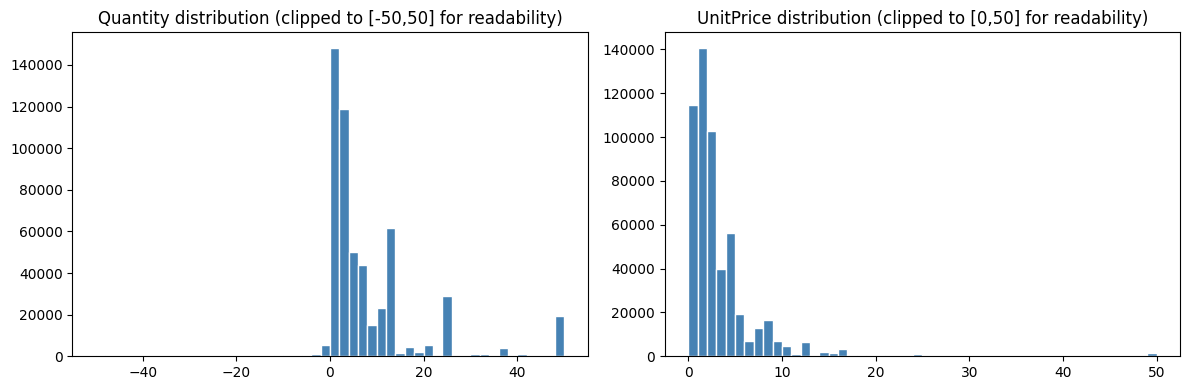

In [35]:
# Distribution of Quantity and UnitPrice (raw, before cleaning)
fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].hist(retail['Quantity'].clip(-50, 50), bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Quantity distribution (clipped to [-50,50] for readability)')
axes[1].hist(retail['UnitPrice'].clip(0, 50), bins=50, color='steelblue', edgecolor='white')
axes[1].set_title('UnitPrice distribution (clipped to [0,50] for readability)')
plt.tight_layout()
plt.show()

Distinct invoices in the raw file: 25,900
count     25900.00
mean        376.36
std        2013.26
min     -168469.60
25%          11.78
50%         207.54
75%         409.08
max      168469.60


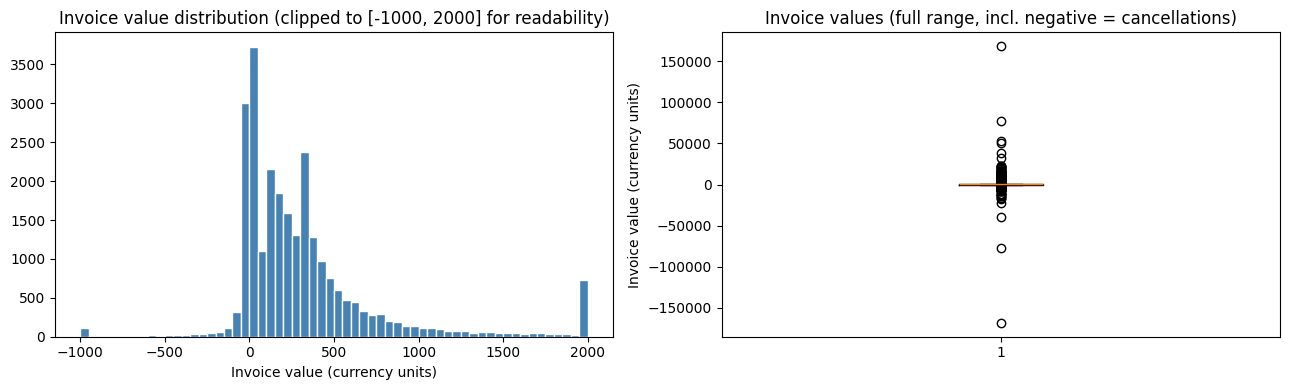

In [ ]:
# Distribution of INVOICE VALUES.
# Task 2 Step 1 asks for the "distribution of invoice values, quantities, unit prices". Quantity
# and UnitPrice are covered above. An invoice can span many line items, so an invoice value is the
# SUM of Quantity x UnitPrice across all of that invoice's rows and not a single row's line total.
retail['LineTotal'] = retail['Quantity'] * retail['UnitPrice']
invoice_values = retail.groupby('InvoiceNo')['LineTotal'].sum()

print(f'Distinct invoices in the raw file: {len(invoice_values):,}')
print(invoice_values.describe().round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13,4))
axes[0].hist(invoice_values.clip(-1000, 2000), bins=60, color='steelblue', edgecolor='white')
axes[0].set_title('Invoice value distribution (clipped to [-1000, 2000] for readability)')
axes[0].set_xlabel('Invoice value (currency units)')
axes[1].boxplot(invoice_values)
axes[1].set_title('Invoice values (full range, incl. negative = cancellations)')
axes[1].set_ylabel('Invoice value (currency units)')
plt.tight_layout()
plt.show()


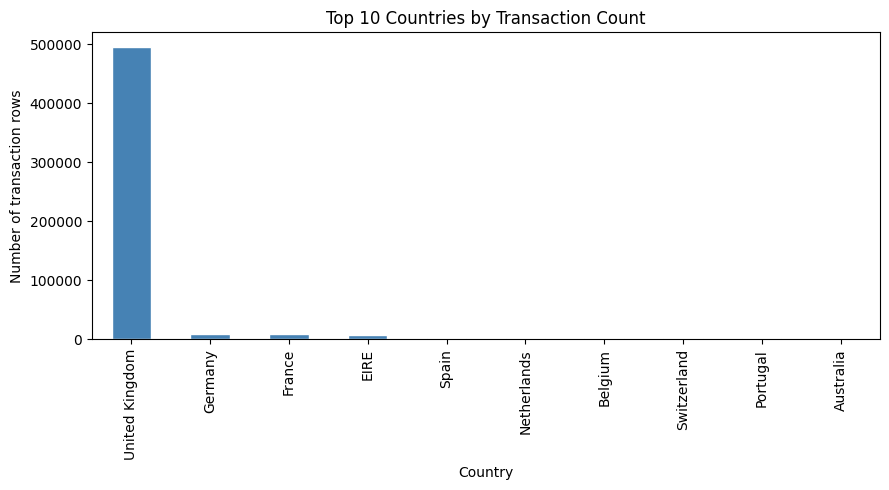

In [37]:
# Top 10 countries by transaction count
plt.figure(figsize=(9,5))
retail['Country'].value_counts().head(10).plot(kind='bar', color='steelblue', edgecolor='white')
plt.title('Top 10 Countries by Transaction Count')
plt.ylabel('Number of transaction rows')
plt.tight_layout()
plt.show()

In [ ]:
# Data quality summary computed on the original raw dataset 
cleaning_summary = pd.DataFrame({
    'Metric': ['Original transaction rows', 'Rows with missing CustomerID', 'Return or cancellation rows',
               'Rows with Quantity <= 0', 'Rows with UnitPrice <= 0', 'Unique customers before cleaning'],
    'Value': [
        len(retail),
        int(retail['CustomerID'].isnull().sum()),
        int(retail['InvoiceNo'].astype(str).str.startswith('C').sum()),
        int((retail['Quantity'] <= 0).sum()),
        int((retail['UnitPrice'] <= 0).sum()),
        int(retail['CustomerID'].nunique())
    ]
})
cleaning_summary

,Metric,Value
0,Original transaction rows,541909
1,Rows with missing CustomerID,135080
2,Return or cancellation rows,9288
3,Rows with Quantity <= 0,10624
4,Rows with UnitPrice <= 0,2517
5,Unique customers before cleaning,4372


### 2.2 Cleanse and Transform the Data

In [ ]:
#  Drop missing CustomerID
before = len(retail)
retail_clean = retail.dropna(subset=['CustomerID']).copy()
retail_clean['CustomerID'] = retail_clean['CustomerID'].astype(int)
print(f'Dropped {before - len(retail_clean):,} rows with missing CustomerID')
print('Remaining rows:', len(retail_clean))

Dropped 135,080 rows with missing CustomerID
Remaining rows: 406829


In [ ]:
#  Flag cancellations and invalid rows
retail_clean['IsCancelled'] = retail_clean['InvoiceNo'].astype(str).str.startswith('C')
retail_clean['IsReturnOrInvalid'] = retail_clean['IsCancelled'] | (retail_clean['Quantity'] <= 0) | (retail_clean['UnitPrice'] <= 0)

print('Cancellation rows          :', retail_clean['IsCancelled'].sum())
print('Quantity <= 0 rows         :', (retail_clean['Quantity'] <= 0).sum())
print('UnitPrice <= 0 rows        :', (retail_clean['UnitPrice'] <= 0).sum())
print('Total return/invalid rows  :', retail_clean['IsReturnOrInvalid'].sum())
print('Unique customers remaining :', retail_clean['CustomerID'].nunique())

Cancellation rows          : 8905
Quantity <= 0 rows         : 8905
UnitPrice <= 0 rows        : 40
Total return/invalid rows  : 8945
Unique customers remaining : 4372


In [ ]:
# Quantity x UnitPrice y.
retail_clean['LineTotal'] = retail_clean['Quantity'] * retail_clean['UnitPrice']
valid_rows = retail_clean.loc[~retail_clean['IsReturnOrInvalid']]

# asking for outliers in "UnitPrice, Quantity, and invoice totals"
invoice_totals_valid = valid_rows.groupby('InvoiceNo')['LineTotal'].sum()

rows = []
for name, series, unit in [
    ('Quantity',     valid_rows['Quantity'],  'transaction rows'),
    ('UnitPrice',    valid_rows['UnitPrice'], 'transaction rows'),
    ('LineTotal',    valid_rows['LineTotal'], 'transaction rows'),
    ('InvoiceTotal', invoice_totals_valid,    'invoices'),
]:
    lo, hi = iqr_bounds(series)
    n_out = int(((series < lo) | (series > hi)).sum())
    rows.append({'Feature': name, 'Unit': unit, 'Lower Bound': lo, 'Upper Bound': hi,
                 'Outliers': n_out, 'Total': len(series), '% Outliers': 100 * n_out / len(series)})

txn_outlier_table = pd.DataFrame(rows).set_index('Feature')
txn_outlier_table.round(2)


,Unit,Lower Bound,Upper Bound,Outliers,Total,% Outliers
Feature,,,,,,
Quantity,transaction rows,-13.00,27.00,25647,397884,6.45
UnitPrice,transaction rows,-2.50,7.50,34356,397884,8.63
LineTotal,transaction rows,-18.00,42.48,31241,397884,7.85
InvoiceTotal,invoices,-312.67,942.54,1466,18532,7.91


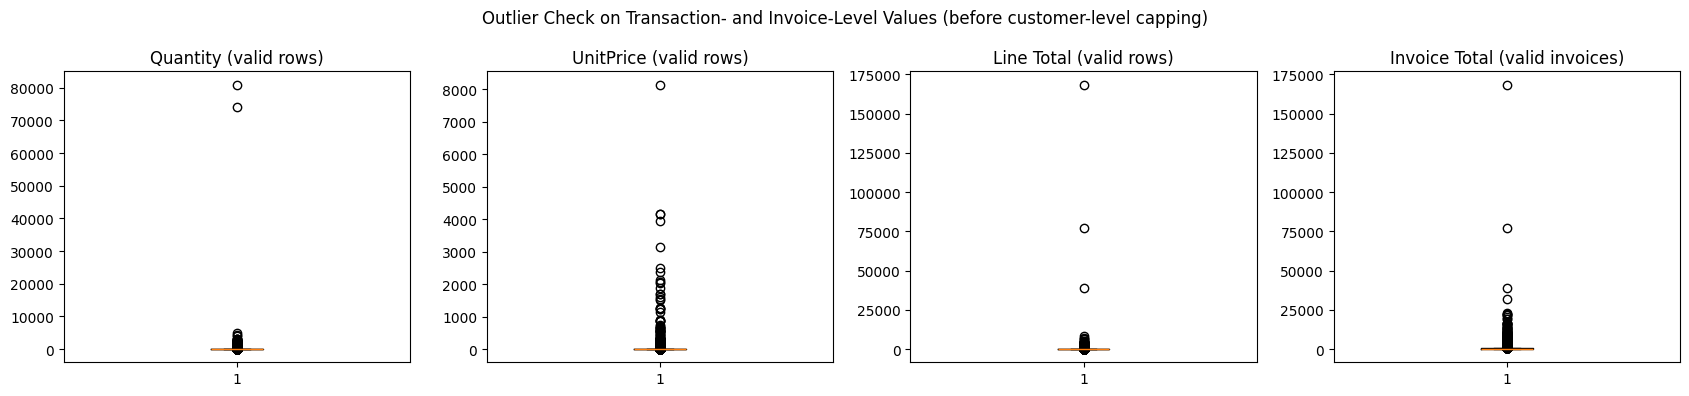

In [42]:
# Four panels: the three row-level measures plus invoice totals
fig, axes = plt.subplots(1, 4, figsize=(17,4))
axes[0].boxplot(valid_rows['Quantity']);   axes[0].set_title('Quantity (valid rows)')
axes[1].boxplot(valid_rows['UnitPrice']);  axes[1].set_title('UnitPrice (valid rows)')
axes[2].boxplot(valid_rows['LineTotal']);  axes[2].set_title('Line Total (valid rows)')
axes[3].boxplot(invoice_totals_valid);     axes[3].set_title('Invoice Total (valid invoices)')
plt.suptitle('Outlier Check on Transaction- and Invoice-Level Values (before customer-level capping)')
plt.tight_layout()
plt.show()


In [ ]:
#  Return rate per customer (based on ALL of that customer's rows)
return_rate = retail_clean.groupby('CustomerID')['IsReturnOrInvalid'].mean().rename('ReturnRate')

#  Keep only valid purchase rows for RFM
valid = retail_clean.loc[~retail_clean['IsReturnOrInvalid']].copy()
print('Valid purchase rows used for RFM:', len(valid))

Valid purchase rows used for RFM: 397884


**Step 5: Feature Engineering (RFM)**

In [ ]:
#  1 day after the last invoice date in the valid data
snapshot_date = valid['InvoiceDate'].max() + pd.Timedelta(days=1)
print('Snapshot date used for Recency:', snapshot_date)

rfm = valid.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('LineTotal', 'sum')
)
rfm['AvgBasketValue'] = rfm['Monetary'] / rfm['Frequency']
rfm = rfm.join(return_rate, how='left').fillna({'ReturnRate': 0})

print('Number of customers available for clustering:', len(rfm))
rfm.describe()

Snapshot date used for Recency: 2011-12-10 12:50:00


Number of customers available for clustering: 4338


,Recency,Frequency,Monetary,AvgBasketValue,ReturnRate
count,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000
mean,92.536422,4.272015,2054.266460,419.166289,0.024856
std,100.014169,7.697998,8989.230441,1796.537944,0.066228
min,1.000000,1.000000,3.750000,3.450000,0.000000
25%,18.000000,1.000000,307.415000,178.625000,0.000000
50%,51.000000,2.000000,674.485000,293.900000,0.000000
75%,142.000000,5.000000,1661.740000,430.113750,0.020177
max,374.000000,209.000000,280206.020000,84236.250000,0.941176


In [ ]:
#here i had to ask myself why does the RFM table have fewer customers than retail_clean?
customers_after_cid_drop = retail_clean['CustomerID'].nunique()
customers_in_rfm = len(rfm)
dropped_ids = set(retail_clean['CustomerID'].unique()) - set(rfm.index)

print(f'Customers remaining after dropping missing CustomerID : {customers_after_cid_drop}')
print(f'Customers with >=1 valid purchase (in RFM table)      : {customers_in_rfm}')
print(f'Customers with NO valid purchase rows (dropped here)  : {len(dropped_ids)}')

Customers remaining after dropping missing CustomerID : 4372
Customers with >=1 valid purchase (in RFM table)      : 4338
Customers with NO valid purchase rows (dropped here)  : 34


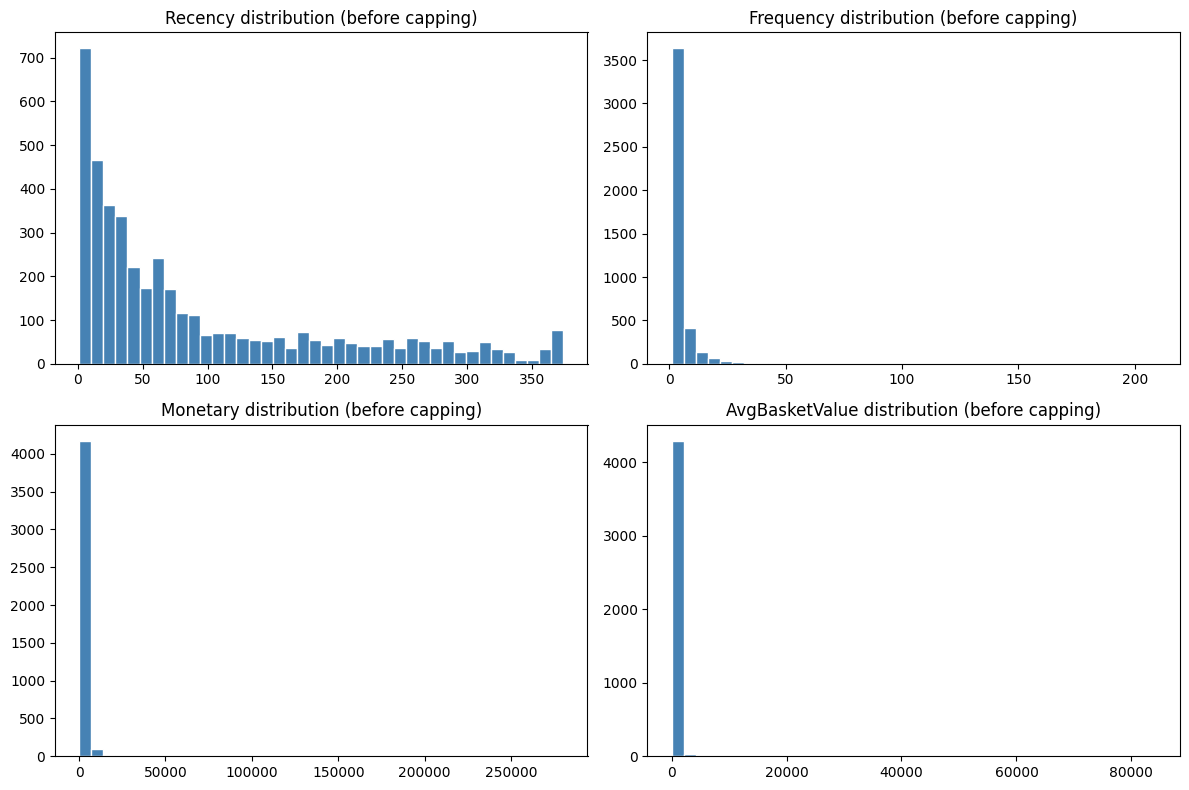

In [46]:
# Distributions of the engineered features (before capping)
fig, axes = plt.subplots(2, 2, figsize=(12,8))
for ax, col in zip(axes.ravel(), ['Recency', 'Frequency', 'Monetary', 'AvgBasketValue']):
    ax.hist(rfm[col], bins=40, color='steelblue', edgecolor='white')
    ax.set_title(f'{col} distribution (before capping)')
plt.tight_layout()
plt.show()

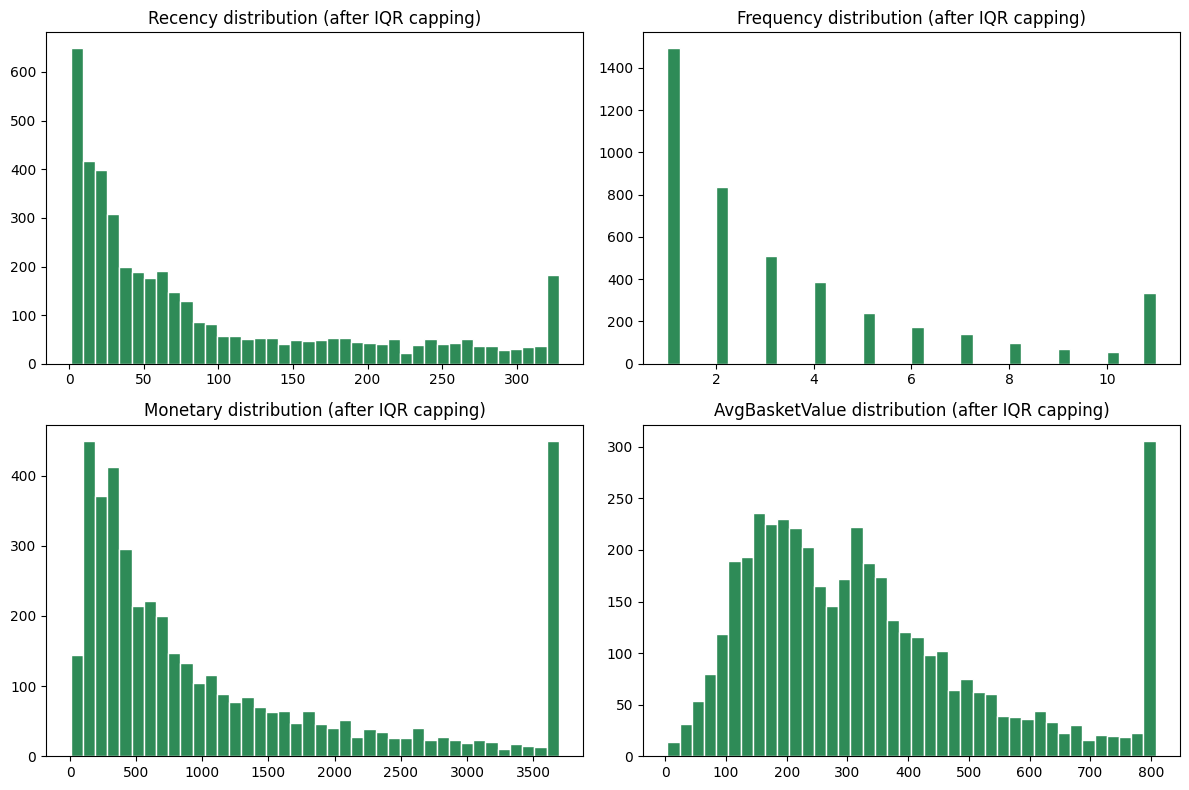

In [47]:
# Cap outliers in the RFM + derived features using IQR
cap_cols = ['Recency', 'Frequency', 'Monetary', 'AvgBasketValue']
rfm_capped = rfm.copy()
for col in cap_cols:
    lo, hi = iqr_bounds(rfm[col])
    rfm_capped[col] = rfm_capped[col].clip(lo, hi)

fig, axes = plt.subplots(2, 2, figsize=(12,8))
for ax, col in zip(axes.ravel(), cap_cols):
    ax.hist(rfm_capped[col], bins=40, color='seagreen', edgecolor='white')
    ax.set_title(f'{col} distribution (after IQR capping)')
plt.tight_layout()
plt.show()

In [48]:
# Scale before distance-based clustering
cluster_features = ['Recency', 'Frequency', 'Monetary', 'AvgBasketValue', 'ReturnRate']
rfm_scaler = StandardScaler()
rfm_scaled = pd.DataFrame(
    rfm_scaler.fit_transform(rfm_capped[cluster_features]),
    columns=cluster_features,
    index=rfm_capped.index
)
rfm_scaled.describe().T[['mean','std','min','max']]

,mean,std,min,max
Recency,7.043185e-17,1.000115,-0.930641,2.433960
Frequency,1.637950e-18,1.000115,-0.818035,2.471699
Monetary,7.206980e-17,1.000115,-1.009777,2.204224
AvgBasketValue,-1.900022e-16,1.000115,-1.628035,2.340002
ReturnRate,4.258670e-17,1.000115,-0.375348,13.837345


### 2.3 Build the Clustering Models

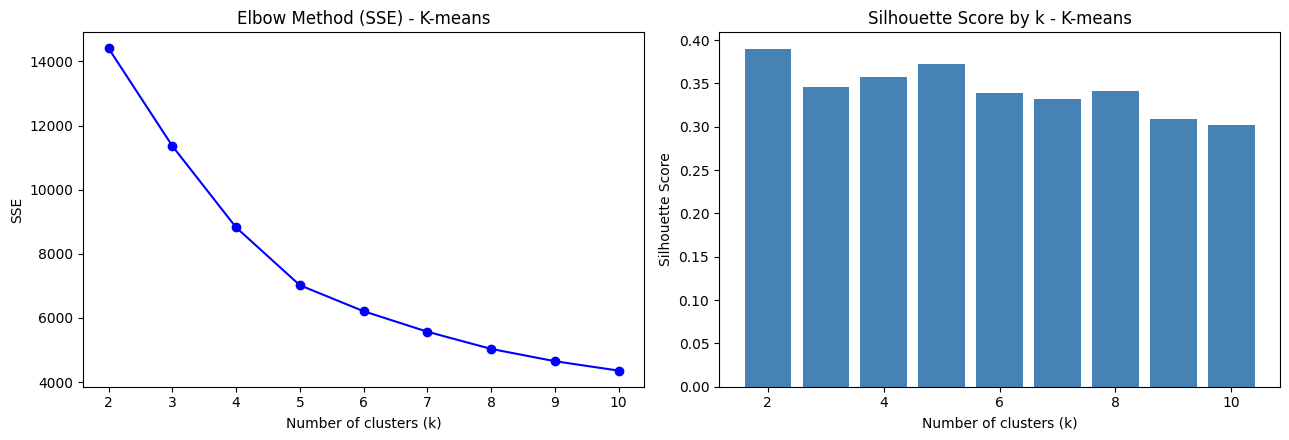

,k,SSE,Silhouette
0,2,14404.971006,0.389392
1,3,11360.484159,0.345841
2,4,8820.648764,0.357483
3,5,7019.758183,0.371889
4,6,6209.449669,0.338467
5,7,5570.496595,0.331878
6,8,5034.450208,0.340753
7,9,4651.002420,0.309433
8,10,4357.296241,0.301550


In [49]:
X_cluster = rfm_scaled.values

sse = []
sil_kmeans = []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X_cluster)
    sse.append(km.inertia_)
    sil_kmeans.append(silhouette_score(X_cluster, labels))

fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
axes[0].plot(list(k_range), sse, 'b-o')
axes[0].set_title('Elbow Method (SSE) - K-means')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('SSE')

axes[1].bar(list(k_range), sil_kmeans, color='steelblue')
axes[1].set_title('Silhouette Score by k - K-means')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

kmeans_scores = pd.DataFrame({'k': list(k_range), 'SSE': sse, 'Silhouette': sil_kmeans})
kmeans_scores

In [50]:
MIN_BUSINESS_K = 4  # need at least this many segments to be useful for targeted marketing actions

global_best_k = int(kmeans_scores.loc[kmeans_scores['Silhouette'].idxmax(), 'k'])
business_range = kmeans_scores[kmeans_scores['k'] >= MIN_BUSINESS_K]
best_k_kmeans = int(business_range.loc[business_range['Silhouette'].idxmax(), 'k'])

print(f'Global best k by silhouette (unconstrained): {global_best_k} (silhouette={kmeans_scores["Silhouette"].max():.4f}) -- too coarse for segmentation')
print(f'Optimal k selected for K-means (best silhouette among k>={MIN_BUSINESS_K}): {best_k_kmeans} '
      f'(silhouette={business_range["Silhouette"].max():.4f})')

kmeans_final = KMeans(n_clusters=best_k_kmeans, n_init=20, random_state=42)
kmeans_labels = kmeans_final.fit_predict(X_cluster)
rfm_capped['KMeans_Cluster'] = kmeans_labels

kmeans_silhouette = silhouette_score(X_cluster, kmeans_labels)
print(f'Final K-means silhouette score: {kmeans_silhouette:.4f}')

Global best k by silhouette (unconstrained): 2 (silhouette=0.3894) -- too coarse for segmentation
Optimal k selected for K-means (best silhouette among k>=4): 5 (silhouette=0.3719)


Final K-means silhouette score: 0.3719


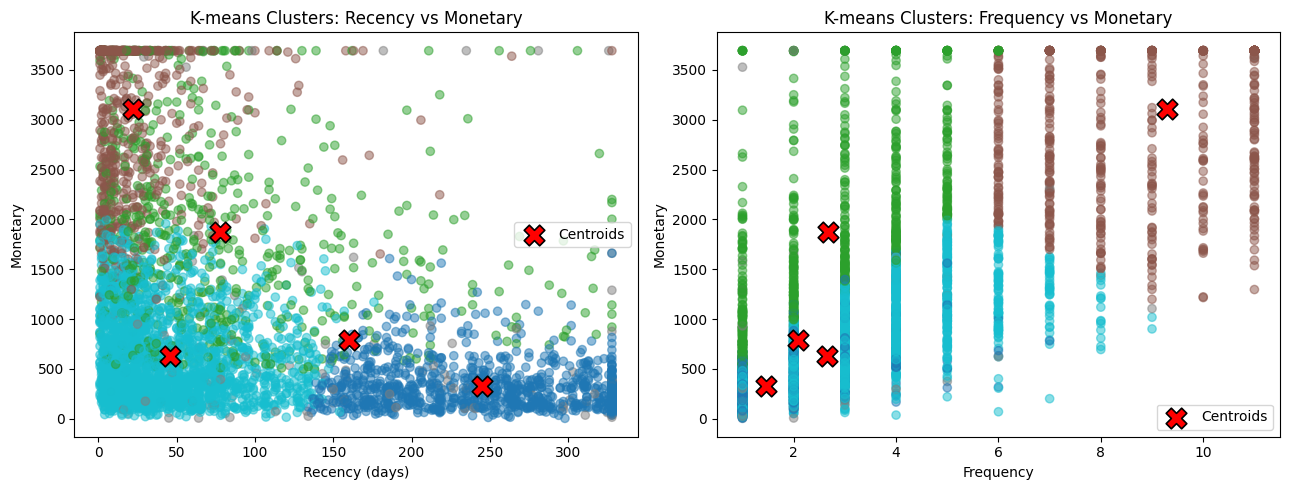

Cluster centroids in original units:


,Recency,Frequency,Monetary,AvgBasketValue,ReturnRate
0,245.08,1.46,330.33,236.06,0.01
1,77.93,2.68,1869.93,659.02,0.02
2,21.92,9.30,3105.83,408.94,0.03
3,160.37,2.09,792.61,320.78,0.37
4,45.54,2.66,632.37,245.12,0.01


In [ ]:
# Cluster centroids plotted
# mapped them back to original units (days / orders / currency) so they can be overlaid on the raw axes.
centroids = pd.DataFrame(
    rfm_scaler.inverse_transform(kmeans_final.cluster_centers_),
    columns=cluster_features
)

fig, axes = plt.subplots(1, 2, figsize=(13,5))
axes[0].scatter(rfm_capped['Recency'], rfm_capped['Monetary'], c=kmeans_labels, cmap='tab10', alpha=0.5)
axes[0].scatter(centroids['Recency'], centroids['Monetary'], s=220, c='red', marker='X',
                edgecolors='black', linewidth=1.2, label='Centroids', zorder=5)
axes[0].set_xlabel('Recency (days)'); axes[0].set_ylabel('Monetary')
axes[0].set_title('K-means Clusters: Recency vs Monetary'); axes[0].legend()

axes[1].scatter(rfm_capped['Frequency'], rfm_capped['Monetary'], c=kmeans_labels, cmap='tab10', alpha=0.5)
axes[1].scatter(centroids['Frequency'], centroids['Monetary'], s=220, c='red', marker='X',
                edgecolors='black', linewidth=1.2, label='Centroids', zorder=5)
axes[1].set_xlabel('Frequency'); axes[1].set_ylabel('Monetary')
axes[1].set_title('K-means Clusters: Frequency vs Monetary'); axes[1].legend()
plt.tight_layout()
plt.show()

print('Cluster centroids in original units:')
centroids.round(2)


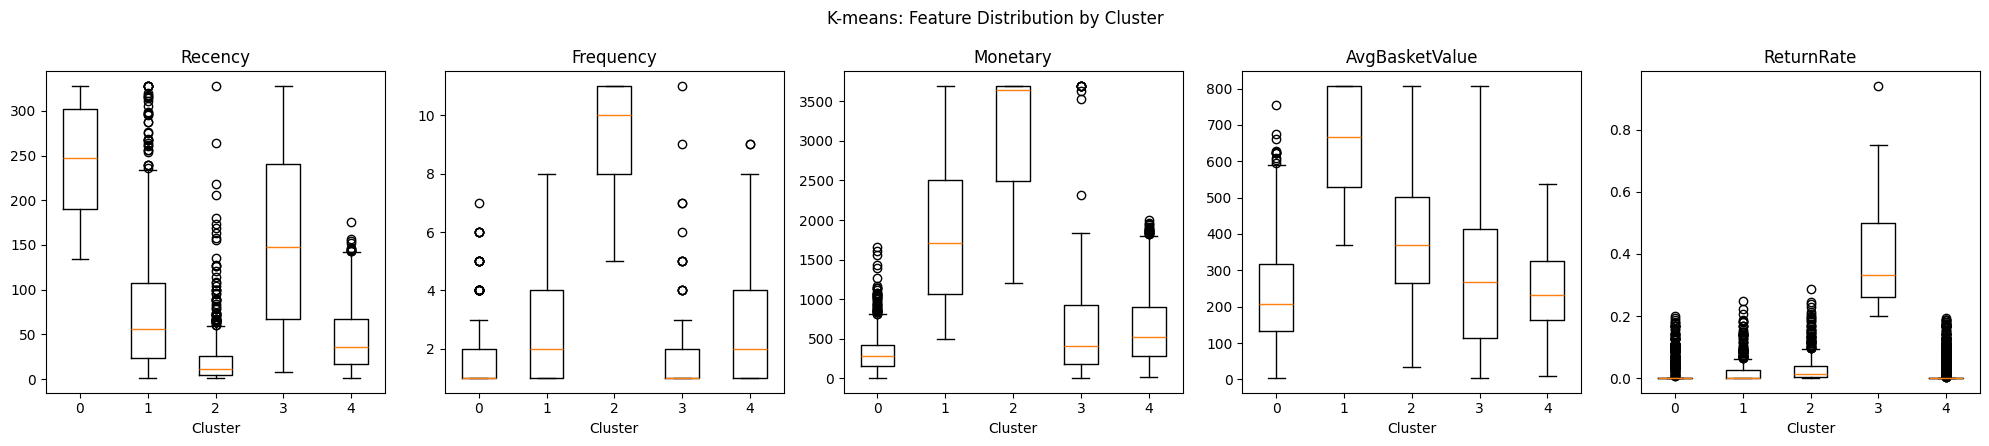

In [52]:
# `labels=` was renamed to `tick_labels=` in Matplotlib 3.9, so setting the tick labels after
# drawing the boxplot avoids a deprecation warning and works on every version.
cluster_ids = sorted(rfm_capped['KMeans_Cluster'].unique())

fig, axes = plt.subplots(1, len(cluster_features), figsize=(4*len(cluster_features), 4.5))
for ax, col in zip(axes, cluster_features):
    data_by_cluster = [rfm_capped.loc[rfm_capped['KMeans_Cluster'] == c, col] for c in cluster_ids]
    ax.boxplot(data_by_cluster)
    ax.set_xticklabels(cluster_ids)
    ax.set_title(col)
    ax.set_xlabel('Cluster')
plt.suptitle('K-means: Feature Distribution by Cluster')
plt.tight_layout()
plt.show()


Linkage computed on 4338 customers -> Z shape (4337, 4)


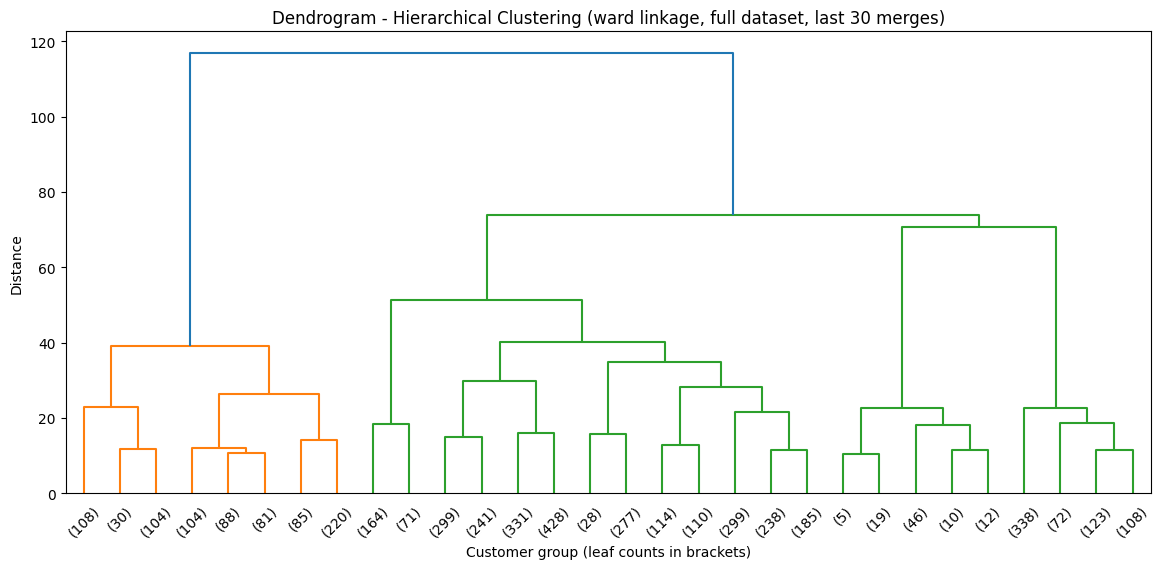

In [ ]:
# Hierarchical linkage is computed on the full customer set and only the drawing is condensed because if all are shown its jjust too messy and hard to look at.
Z = shc.linkage(X_cluster, method='ward')
print('Linkage computed on', X_cluster.shape[0], 'customers -> Z shape', Z.shape)

plt.figure(figsize=(14, 6))
shc.dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True)
plt.title('Dendrogram - Hierarchical Clustering (ward linkage, full dataset, last 30 merges)')
plt.xlabel('Customer group (leaf counts in brackets)')
plt.ylabel('Distance')
plt.show()

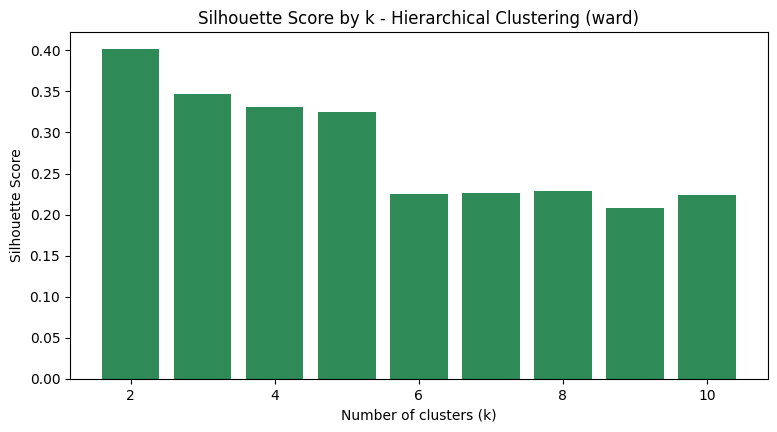

,k,Silhouette
0,2,0.402053
1,3,0.346974
2,4,0.331493
3,5,0.325007
4,6,0.225492
5,7,0.226330
6,8,0.228423
7,9,0.207619
8,10,0.223830


In [54]:
sil_hier = []
hier_k_range = range(2, 11)

for k in hier_k_range:
    ac = AgglomerativeClustering(n_clusters=k, linkage='ward')
    labels = ac.fit_predict(X_cluster)
    sil_hier.append(silhouette_score(X_cluster, labels))

plt.figure(figsize=(9,4.5))
plt.bar(list(hier_k_range), sil_hier, color='seagreen')
plt.xlabel('Number of clusters (k)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score by k - Hierarchical Clustering (ward)')
plt.show()

hier_scores = pd.DataFrame({'k': list(hier_k_range), 'Silhouette': sil_hier})
hier_scores

In [55]:
global_best_k_hier = int(hier_scores.loc[hier_scores['Silhouette'].idxmax(), 'k'])
business_range_hier = hier_scores[hier_scores['k'] >= MIN_BUSINESS_K]
best_k_hier = int(business_range_hier.loc[business_range_hier['Silhouette'].idxmax(), 'k'])

print(f'Global best k by silhouette (unconstrained): {global_best_k_hier} (silhouette={hier_scores["Silhouette"].max():.4f}) -- same trivial 2-way split issue as K-means')
print(f'Optimal k selected for Hierarchical Clustering (best silhouette among k>={MIN_BUSINESS_K}): {best_k_hier} '
      f'(silhouette={business_range_hier["Silhouette"].max():.4f})')

hier_final = AgglomerativeClustering(n_clusters=best_k_hier, linkage='ward')
hier_labels = hier_final.fit_predict(X_cluster)
rfm_capped['Hier_Cluster'] = hier_labels

hier_silhouette = silhouette_score(X_cluster, hier_labels)
print(f'Final Hierarchical Clustering silhouette score: {hier_silhouette:.4f}')

Global best k by silhouette (unconstrained): 2 (silhouette=0.4021) -- same trivial 2-way split issue as K-means
Optimal k selected for Hierarchical Clustering (best silhouette among k>=4): 4 (silhouette=0.3315)


Final Hierarchical Clustering silhouette score: 0.3315


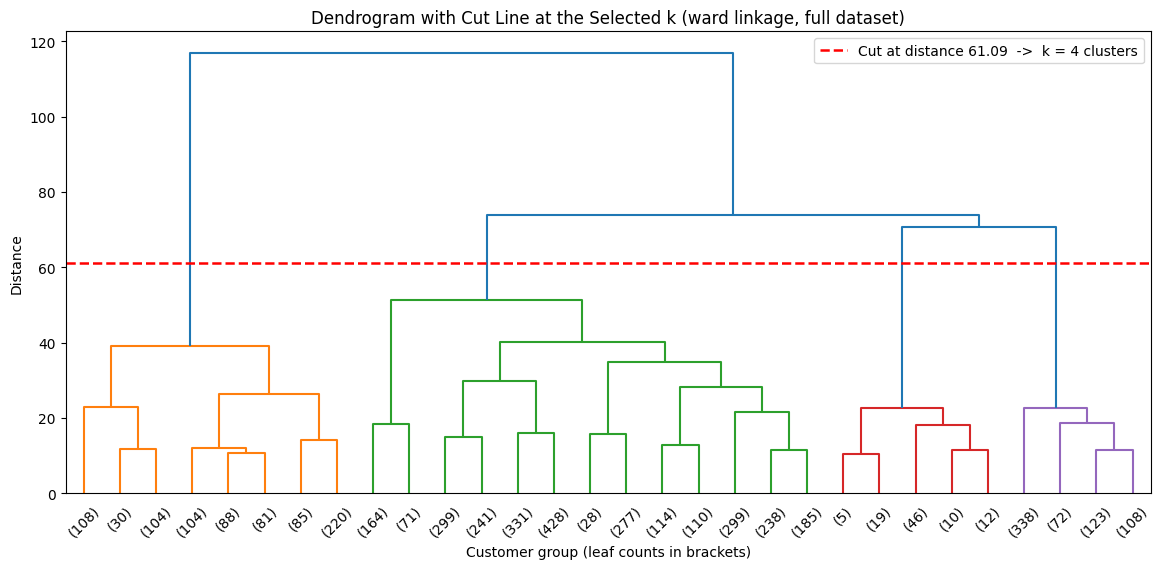

Ten largest merge distances (largest last): [np.float64(26.36), np.float64(28.16), np.float64(29.93), np.float64(34.82), np.float64(39.22), np.float64(40.07), np.float64(51.39), np.float64(70.79), np.float64(73.99), np.float64(116.76)]
Cutting anywhere between 51.39 and 70.79 produces k=4.
Cluster sizes cutting the dendrogram : [2785, 820, 641, 92]
Cluster sizes from AgglomerativeClustering: [2785, 820, 641, 92]


In [ ]:
# Dendrogram redrawn with a cut line at the selected k.

cut_height = (Z[-best_k_hier, 2] + Z[-(best_k_hier - 1), 2]) / 2

plt.figure(figsize=(14, 6))
shc.dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True,
               color_threshold=cut_height)
plt.axhline(y=cut_height, color='red', linestyle='--', linewidth=1.8,
            label=f'Cut at distance {cut_height:.2f}  ->  k = {best_k_hier} clusters')
plt.title('Dendrogram with Cut Line at the Selected k (ward linkage, full dataset)')
plt.xlabel('Customer group (leaf counts in brackets)')
plt.ylabel('Distance')
plt.legend()
plt.show()

print('Ten largest merge distances (largest last):', [round(h, 2) for h in Z[-10:, 2]])
print(f'Cutting anywhere between {Z[-best_k_hier, 2]:.2f} and {Z[-(best_k_hier-1), 2]:.2f} '
      f'produces k={best_k_hier}.')

# Confirm the tree agrees with the AgglomerativeClustering labels used for the results above.
from scipy.cluster.hierarchy import fcluster
sizes_from_tree = pd.Series(fcluster(Z, t=best_k_hier, criterion='maxclust')).value_counts()
sizes_from_model = pd.Series(hier_labels).value_counts()
print('Cluster sizes cutting the dendrogram :', sorted(sizes_from_tree.tolist(), reverse=True))
print('Cluster sizes from AgglomerativeClustering:', sorted(sizes_from_model.tolist(), reverse=True))

In [ ]:
# The linkage comparison reports cluster size alongside silhouette, because silhouette alone is
# not sufficient to choose a segmentation so a solution that isolates a handful of extreme customers
# into singleton clusters scores well on silhouette yet is useless for marketing. 

linkage_rows = []
for link in ['ward', 'average', 'complete']:
    ac_l = AgglomerativeClustering(n_clusters=best_k_hier, linkage=link)
    lab_l = ac_l.fit_predict(X_cluster)
    sizes = pd.Series(lab_l).value_counts().sort_values(ascending=False).tolist()
    linkage_rows.append({
        'Linkage': link,
        'Silhouette': silhouette_score(X_cluster, lab_l),
        'Largest cluster': sizes[0],
        '% in largest': 100 * sizes[0] / len(lab_l),
        'Smallest cluster': sizes[-1],
        'Clusters with <10 customers': sum(1 for s in sizes if s < 10),
        'Cluster sizes': sizes,
    })

linkage_comparison = pd.DataFrame(linkage_rows).set_index('Linkage')
linkage_comparison.round(4)


,Silhouette,Largest cluster,% in largest,Smallest cluster,Clusters with <10 customers,Cluster sizes
Linkage,,,,,,
ward,0.3315,2785,64.2001,92,0,"[2785, 820, 641, 92]"
average,0.5560,4245,97.8562,1,2,"[4245, 91, 1, 1]"
complete,0.3807,4175,96.2425,1,1,"[4175, 124, 38, 1]"


### 2.4 Evaluate and Compare the Models

In [ ]:
# The model comparison includes cluster size as well as silhouette. A single silhouette number is
# not enough to prefer one algorithm over another as the linkage comparison above showed, a high
# silhouette can come from a degenerate split. Reporting sizes makes the preference defensible.
km_sizes   = rfm_capped['KMeans_Cluster'].value_counts().sort_values(ascending=False).tolist()
hier_sizes = rfm_capped['Hier_Cluster'].value_counts().sort_values(ascending=False).tolist()

comparison = pd.DataFrame({
    'Model': ['K-means', 'Hierarchical (ward)'],
    'Optimal k': [best_k_kmeans, best_k_hier],
    'Silhouette Score': [kmeans_silhouette, hier_silhouette],
    'Largest cluster': [km_sizes[0], hier_sizes[0]],
    '% in largest': [100*km_sizes[0]/len(rfm_capped), 100*hier_sizes[0]/len(rfm_capped)],
    'Smallest cluster': [km_sizes[-1], hier_sizes[-1]],
    'Cluster sizes': [km_sizes, hier_sizes],
})
comparison.round(4)


,Model,Optimal k,Silhouette Score,Largest cluster,% in largest,Smallest cluster,Cluster sizes
0,K-means,5,0.3719,1960,45.1821,94,"[1960, 924, 715, 645, 94]"
1,Hierarchical (ward),4,0.3315,2785,64.2001,92,"[2785, 820, 641, 92]"


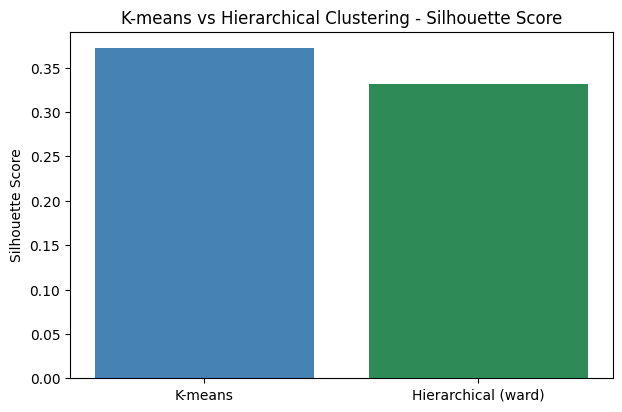

Preferred model for further exploration: K-means


In [59]:
plt.figure(figsize=(7,4.5))
plt.bar(comparison['Model'], comparison['Silhouette Score'], color=['steelblue','seagreen'])
plt.ylabel('Silhouette Score')
plt.title('K-means vs Hierarchical Clustering - Silhouette Score')
plt.show()

preferred_model = 'K-means' if kmeans_silhouette >= hier_silhouette else 'Hierarchical (ward)'
preferred_col = 'KMeans_Cluster' if preferred_model == 'K-means' else 'Hier_Cluster'
print(f'Preferred model for further exploration: {preferred_model}')

In [60]:
same_k = pd.merge(
    kmeans_scores[['k', 'Silhouette']],
    hier_scores[['k', 'Silhouette']],
    on='k', suffixes=(' (K-means)', ' (Hierarchical)')
)
same_k = same_k[same_k['k'] >= MIN_BUSINESS_K].reset_index(drop=True)
same_k['Difference (K-means - Hierarchical)'] = (
    same_k['Silhouette (K-means)'] - same_k['Silhouette (Hierarchical)']
)
same_k.round(4)

,k,Silhouette (K-means),Silhouette (Hierarchical),Difference (K-means - Hierarchical)
0,4,0.3575,0.3315,0.0260
1,5,0.3719,0.3250,0.0469
2,6,0.3385,0.2255,0.1130
3,7,0.3319,0.2263,0.1055
4,8,0.3408,0.2284,0.1123
5,9,0.3094,0.2076,0.1018
6,10,0.3016,0.2238,0.0777


### 2.5 Summarize and Interpret

In [ ]:
# Descriptive statistics use the original) RFM values 
# its comes from the capped/scaled clustering input. 

rfm_labeled = rfm.copy()
rfm_labeled[preferred_col] = rfm_capped[preferred_col]

profile = rfm_labeled.groupby(preferred_col)[cluster_features].mean()
profile['Customers'] = rfm_labeled.groupby(preferred_col).size()
profile = profile.sort_values('Monetary', ascending=False)

profile.round(2)

,Recency,Frequency,Monetary,AvgBasketValue,ReturnRate,Customers
KMeans_Cluster,,,,,,
2,21.98,14.05,7850.21,477.63,0.03,715
3,163.32,2.14,2408.03,1485.62,0.37,94
1,78.14,2.68,2368.65,990.46,0.02,645
4,45.51,2.66,632.22,245.01,0.01,1960
0,249.74,1.46,330.33,236.06,0.01,924


**Naming the segments.** The names below are read directly off the profile table above -- each one
is justified by that cluster's own numbers relative to the other four, not chosen in advance:

| Cluster | Evidence from the table | Segment name |
|---|---|---|
| 2 | Lowest recency (22 days), by far the highest frequency (14.1 orders) and spend (7,850) | **High-Value Loyal** |
| 3 | Highest return rate by a wide margin (37%), long lapsed (163 days), very large baskets | **Return-Prone Big-Basket** |
| 1 | Mid spend (2,369) but a high average basket (990) on only 2.7 orders | **Premium Occasional** |
| 4 | Largest group (1,960), fairly recent (46 days) but low spend (632) and small baskets | **Recent Low-Value** |
| 0 | Longest lapsed (250 days), fewest orders (1.5), lowest spend (330) | **At-Risk Low-Value** |


In [ ]:
# Attach the names decided abovetogether so it looks nice
segment_names = {
    2: 'High-Value Loyal',
    3: 'Return-Prone Big-Basket',
    1: 'Premium Occasional',
    4: 'Recent Low-Value',
    0: 'At-Risk Low-Value',
}

profile['Segment Name'] = profile.index.map(segment_names)
profile = profile[['Segment Name', 'Customers', 'Recency', 'Frequency',
                   'Monetary', 'AvgBasketValue', 'ReturnRate']]
profile.round(2)

,Segment Name,Customers,Recency,Frequency,Monetary,AvgBasketValue,ReturnRate
KMeans_Cluster,,,,,,,
2,High-Value Loyal,715,21.98,14.05,7850.21,477.63,0.03
3,Return-Prone Big-Basket,94,163.32,2.14,2408.03,1485.62,0.37
1,Premium Occasional,645,78.14,2.68,2368.65,990.46,0.02
4,Recent Low-Value,1960,45.51,2.66,632.22,245.01,0.01
0,At-Risk Low-Value,924,249.74,1.46,330.33,236.06,0.01


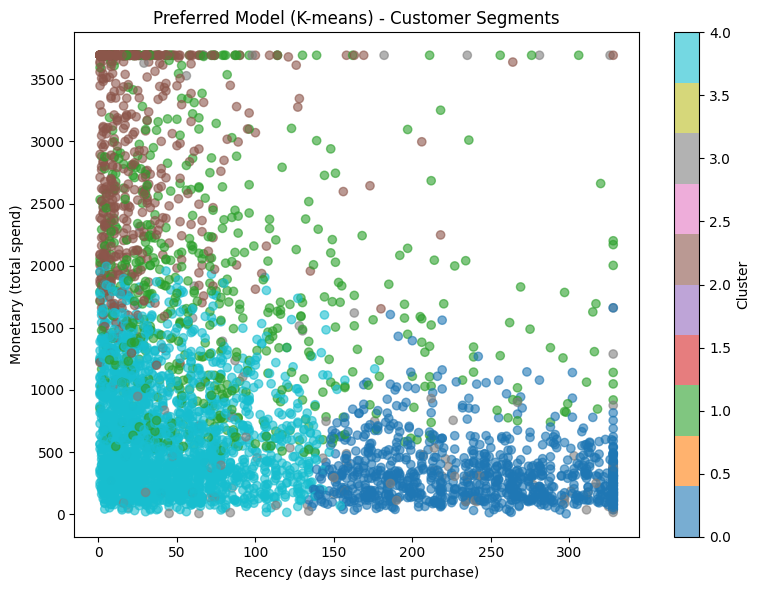

In [63]:
# Visualise the final preferred segments
plt.figure(figsize=(8,6))
scatter = plt.scatter(rfm_capped['Recency'], rfm_capped['Monetary'], c=rfm_capped[preferred_col], cmap='tab10', alpha=0.6)
plt.xlabel('Recency (days since last purchase)')
plt.ylabel('Monetary (total spend)')
plt.title(f'Preferred Model ({preferred_model}) - Customer Segments')
plt.colorbar(scatter, label='Cluster')
plt.tight_layout()
plt.show()

**Segment interpretation and recommended business actions.** Monetary values are in currency
units 

- High-Value Loyal (cluster 2, 715 customers) 22 days since last purchase, 14.1 orders,
  7,850 total spend, 478 average basket, 3.0% returns.
  Action: protect this segment with loyalty rewards, early access to new products and
  premium/personalised service. They are the most valuable customers to retain, and losing one
  costs far more than a discount would.

- Return-Prone Big-Basket (cluster 3, 94 customers) 163 days since last purchase, 2.1
  orders, 2,408 total spend, 1,486 average basket, 37.4% returns.
  Action: investigate product descriptions, sizing information and delivery quality before
  running any promotion. At a 37% return rate, driving more volume into this segment would
  probably destroy margin rather than create it. Fix the cause first.

- Premium Occasional (cluster 1, 645 customers) 78 days since last purchase, 2.7 orders,
  2,369 total spend, 990 average basket, 2.0% returns.
  *Action:* grow purchase frequency through cross selling and premium product recommendations. These
  customers clearly buy large baskets when they do buy, the opportunity is the gap between visits,
  not the size of the order.

- Recent Low-Value (cluster 4, 1,960 customers) the largest segment, 46 days since last
  purchase, 2.7 orders, 632 total spend, 245 average basket, 1.4% returns.
  *Action:* nudge a second or third purchase with bundle offers or first repeat purchase
  incentives while interest is still fresh. Because this is the biggest group, even a small
  percentage lift here outweighs a large lift in a small segment.

- At-Risk Low-Value (cluster 0, 924 customers) 250 days since last purchase, 1.5 orders,
  330 total spend, 236 average basket, 1.3% returns.
  *Action:* run low cost win back campaigns such as reminder emails or small vouchers. Given the
  long inactivity and low historical spend, expensive loyalty investment is unlikely to pay back.

Further improvements: country specific segmentation (the data is heavily UK dominated),
periodic rescoring of RFM as customer behaviour changes over time, and validating the segments
against actual campaign response and retention outcomes rather than clustering metrics alone.



- Transaction-level data (541,909 rows) was cleaned (missing `CustomerID` dropped, cancellations
  and invalid Quantity/UnitPrice rows excluded from Monetary/Frequency but retained for the
  Return Rate feature) and aggregated to the customer level.
- Engineered features: Recency, Frequency, Monetary, Average Basket Value, Return Ratecapped
  with IQR and standardized before clustering.
- Two clustering models were built and compared on the same feature set: K-means and
  Hierarchical (ward) Clustering, each with `k` chosen via silhouette score.
- The model with the higher silhouette score was carried forward, producing business-interpretable
  segments with concrete recommended actions per segment (in tables above).